In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
device = "ibm_torino"
# device = "ibm_marrakesh"

fractional_gates = False

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device, use_fractional_gates=fractional_gates)

# Simulation settings

In [3]:
from z2chain.gdd import random, constant, counteract_rotation, zero_mean
from z2chain.postselection import bias_corrected_get_recovered_samples_dicts
from utils.hexec import ExecDB
from functools import partial

L = 21
J = 2
h = 0.8
lamb = 1

x_basis = False

particle_pair_left_position = L//2 - 3
particle_pair_length = 6

dt = 0.125
steps = 40
desired_error = 1e-2
final_time = steps * dt
print(f"Final time: {final_time}")

shots = 75000
confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = None
# recovery = bias_corrected_get_recovered_samples_dicts
recovery = True
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean
# g_func = None

# if callable(g_func):
#     g_func.__name__ = "from_matrix"

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": shots//100,
        "shots_per_randomization": 100
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

execution_database = "z2_chain_jobs_mpf_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

curated_data_folder_path = "Curated Data/"

Final time: 5.0


# Error guarantees

In [4]:
from z2chain.circs import nlayers_trotter, alpha_commutator
import numpy as np

desired_precision = 1e-2

max_pf_layers = int(np.ceil(final_time / dt))
required_pf_layers = int(np.ceil(nlayers_trotter(final_time, desired_precision, L, J, h, lamb)))
original_alpha_comm = alpha_commutator(L, J, h, lamb)

ɑ_true = 134.13333333333327


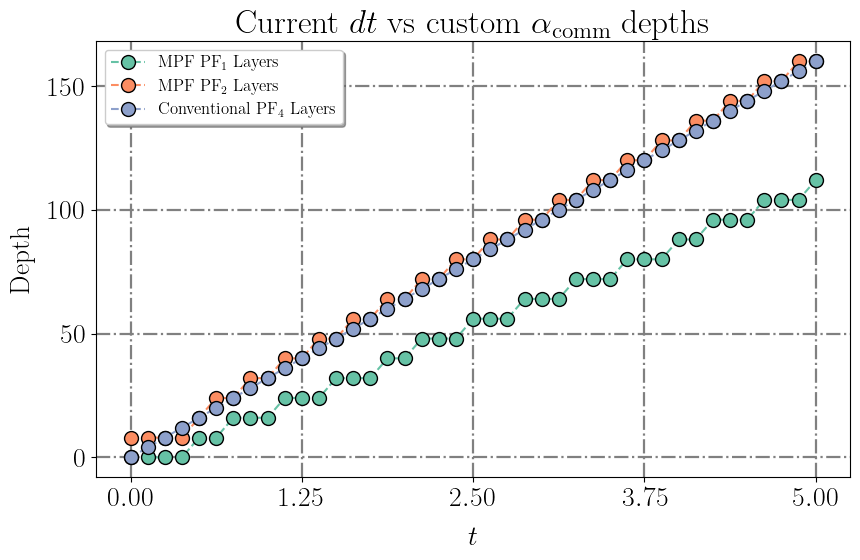

In [5]:
from z2chain.circs import alpha_commutator
import utils.multiproductf as mpf
import numpy as np

alpha_comm = float(alpha_commutator(L, J, h, lamb))
print(f"ɑ_true = {alpha_comm}")

# custom_alpha_comm = alpha_comm
custom_alpha_comm = 4

t_arr = np.linspace(0, final_time, steps+1)
# ks, coeffs = mpf.get_ks_coeffs_improvement(t_arr, custom_alpha_comm, 2, 3, 2)
ks, coeffs = mpf.get_ks_maxk_dt(t_arr, dt, 2, 3, 2)

# Force even
corrected_ks = np.zeros_like(ks)
for i in range(ks.shape[1]):
    this_ks_col = ks[:, i].copy()
    if i < (corrected_ks.shape[1]-1):
        this_ks_col[~np.equal(this_ks_col % 2, 0)] -= 1
    else:
        this_ks_col[~np.equal(this_ks_col % 2, 0)] += 1
    corrected_ks[:, i] = this_ks_col

corrected_coeffs = np.zeros_like(coeffs)
for i in range(corrected_ks.shape[0]):
    if corrected_ks[i, 0] == 0:
        corrected_coeffs[i, -1] = 1
    else:
        corrected_coeffs[i] = mpf.mpfcoeffs(corrected_ks[i], 2)[0]

mpf.plt_mpf_conventional_comparison(t_arr, corrected_ks, dt, 4, x_label=r"$t$", title=r"Current $dt$ vs custom $\alpha_{\mathrm{comm}}$ depths", y_label=r"Depth")

# Circuit transpilation, observables & postselection

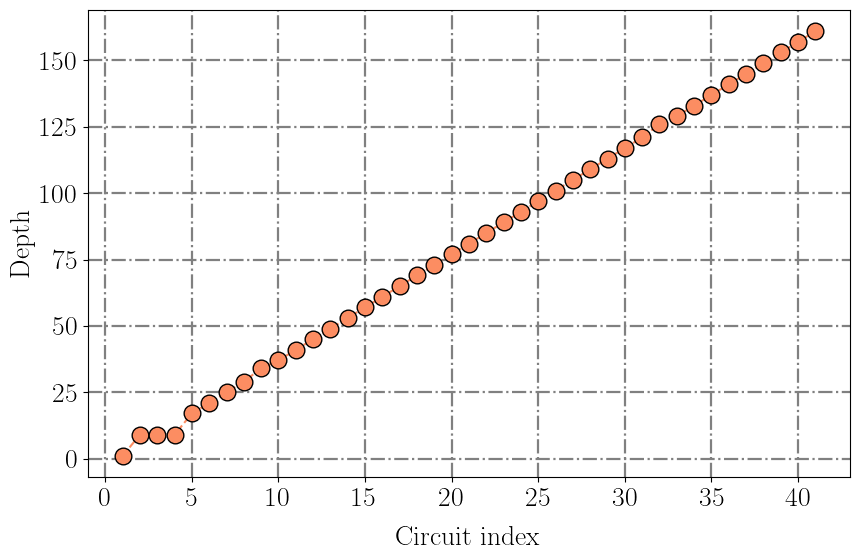

In [6]:
from z2chain.circs import string_quench_simulation_circuits_mpf, string_quench_simulation_and_odr_circs_mpf
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
from utils.circs import numpy_array_of_circuits
import numpy as np
import os

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, J, h, lamb, dt, ks[1::], backend, optimization_level, g_func, particle_pair_left_position, particle_pair_length, layout, x_basis, False)
extra_options = {"backend": device, "L": L, "J": J, "h": h, "lamb": lamb, "g": g_func.__name__ if callable(g_func) else g_func, "particle_pair_left_position": particle_pair_left_position, "particle_pair_length": particle_pair_length, "final_time": final_time, "dt": dt, "steps": steps}
if odr:
    circuits, odr_circuits = string_quench_simulation_and_odr_circs_mpf(*circs_args)
else:
    circuits = string_quench_simulation_circuits_mpf(*circs_args)

circuits = numpy_array_of_circuits(circuits)
odr_circuits = numpy_array_of_circuits(odr_circuits)

observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)
plot_circuit_arr_depth(circuits[:, 1])

### Send jobs to hardware

In [6]:
from utils.postselection_multithreaded import execute_postselected_sampler_batch

flatten_circuits = circuits.flatten()

if odr:
    flatten_odr_circuits = odr_circuits.flatten()
    jobs = execute_postselected_sampler_batch(backend, sampler_options, flatten_circuits, postselection_operators_func, observable_generating_funcs, odr_circuits=flatten_odr_circuits, extra_options=extra_options, job_db=job_db)
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, flatten_circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, job_db=job_db)

print(f"Sent {len(jobs)} jobs")

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:822: UserWarning: The backend ibm_marrakesh currently has a status of internal.
  warnings.warn(


Sent 164 jobs


### Load jobs with the same options

In [7]:
from utils.postselection_multithreaded import load_postselected_jobs
import pickle
import os

# MPF means that things are organized in the same way as flatten_circuits

job_index = 0

verbose = True
overwrite = True
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2chainquench_mpf_curated_data_{device}_L_{L}_J_{J}_h_{h}_lamb_{lamb}_g_{g_func.__name__ if callable(g_func) else None}_final_time_{final_time}_dt_{dt}_steps_{steps}_shots_{shots}_ppos_{particle_pair_left_position}_pl_{particle_pair_length}_ft_{flip_threshold}_DD_{sampler_options["dynamical_decoupling"]["enable"]}_PT_{sampler_options["twirling"]["enable_gates"]}_pODR_{postselect_odr}.pkl")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    flatten_circuits = circuits.flatten()
    flatten_odr_circuits = odr_circuits.flatten()
    if odr:
        mpf_observables, mpf_observables_confidence, samples_dicts_mpf, postselected_samples_dicts_mpf, layout_mpf = load_postselected_jobs(job_db, service, sampler_options, flatten_circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=flatten_odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, job_index=job_index, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=verbose)
    else:
        mpf_observables, mpf_observables_confidence, samples_dicts_mpf, postselected_samples_dicts_mpd, layout_mpf = load_postselected_jobs(job_db, service, sampler_options, flatten_circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, job_index=job_index, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=verbose)

    observables = np.zeros((corrected_ks.shape[0], len(observable_generating_funcs)))
    observables_confidence = np.zeros_like(observables)
    for i in range(observables.shape[0]):
        observables[i] = np.sum(mpf_observables[0][i*corrected_ks.shape[1]:(i+1)*corrected_ks.shape[1], :] * corrected_coeffs[i, :].reshape((-1, 1)), axis=0)
        # TODO: Really addressing this
        # observables_confidence[i] = mpf_observables_confidence[i, 0]

    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts_mpf, postselected_samples_dicts_mpf, layout_mpf), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts_mpf, postselected_samples_dicts_mpf, layout_mpf = pickle.load(f)

Loaded 164 jobs                                                                                    


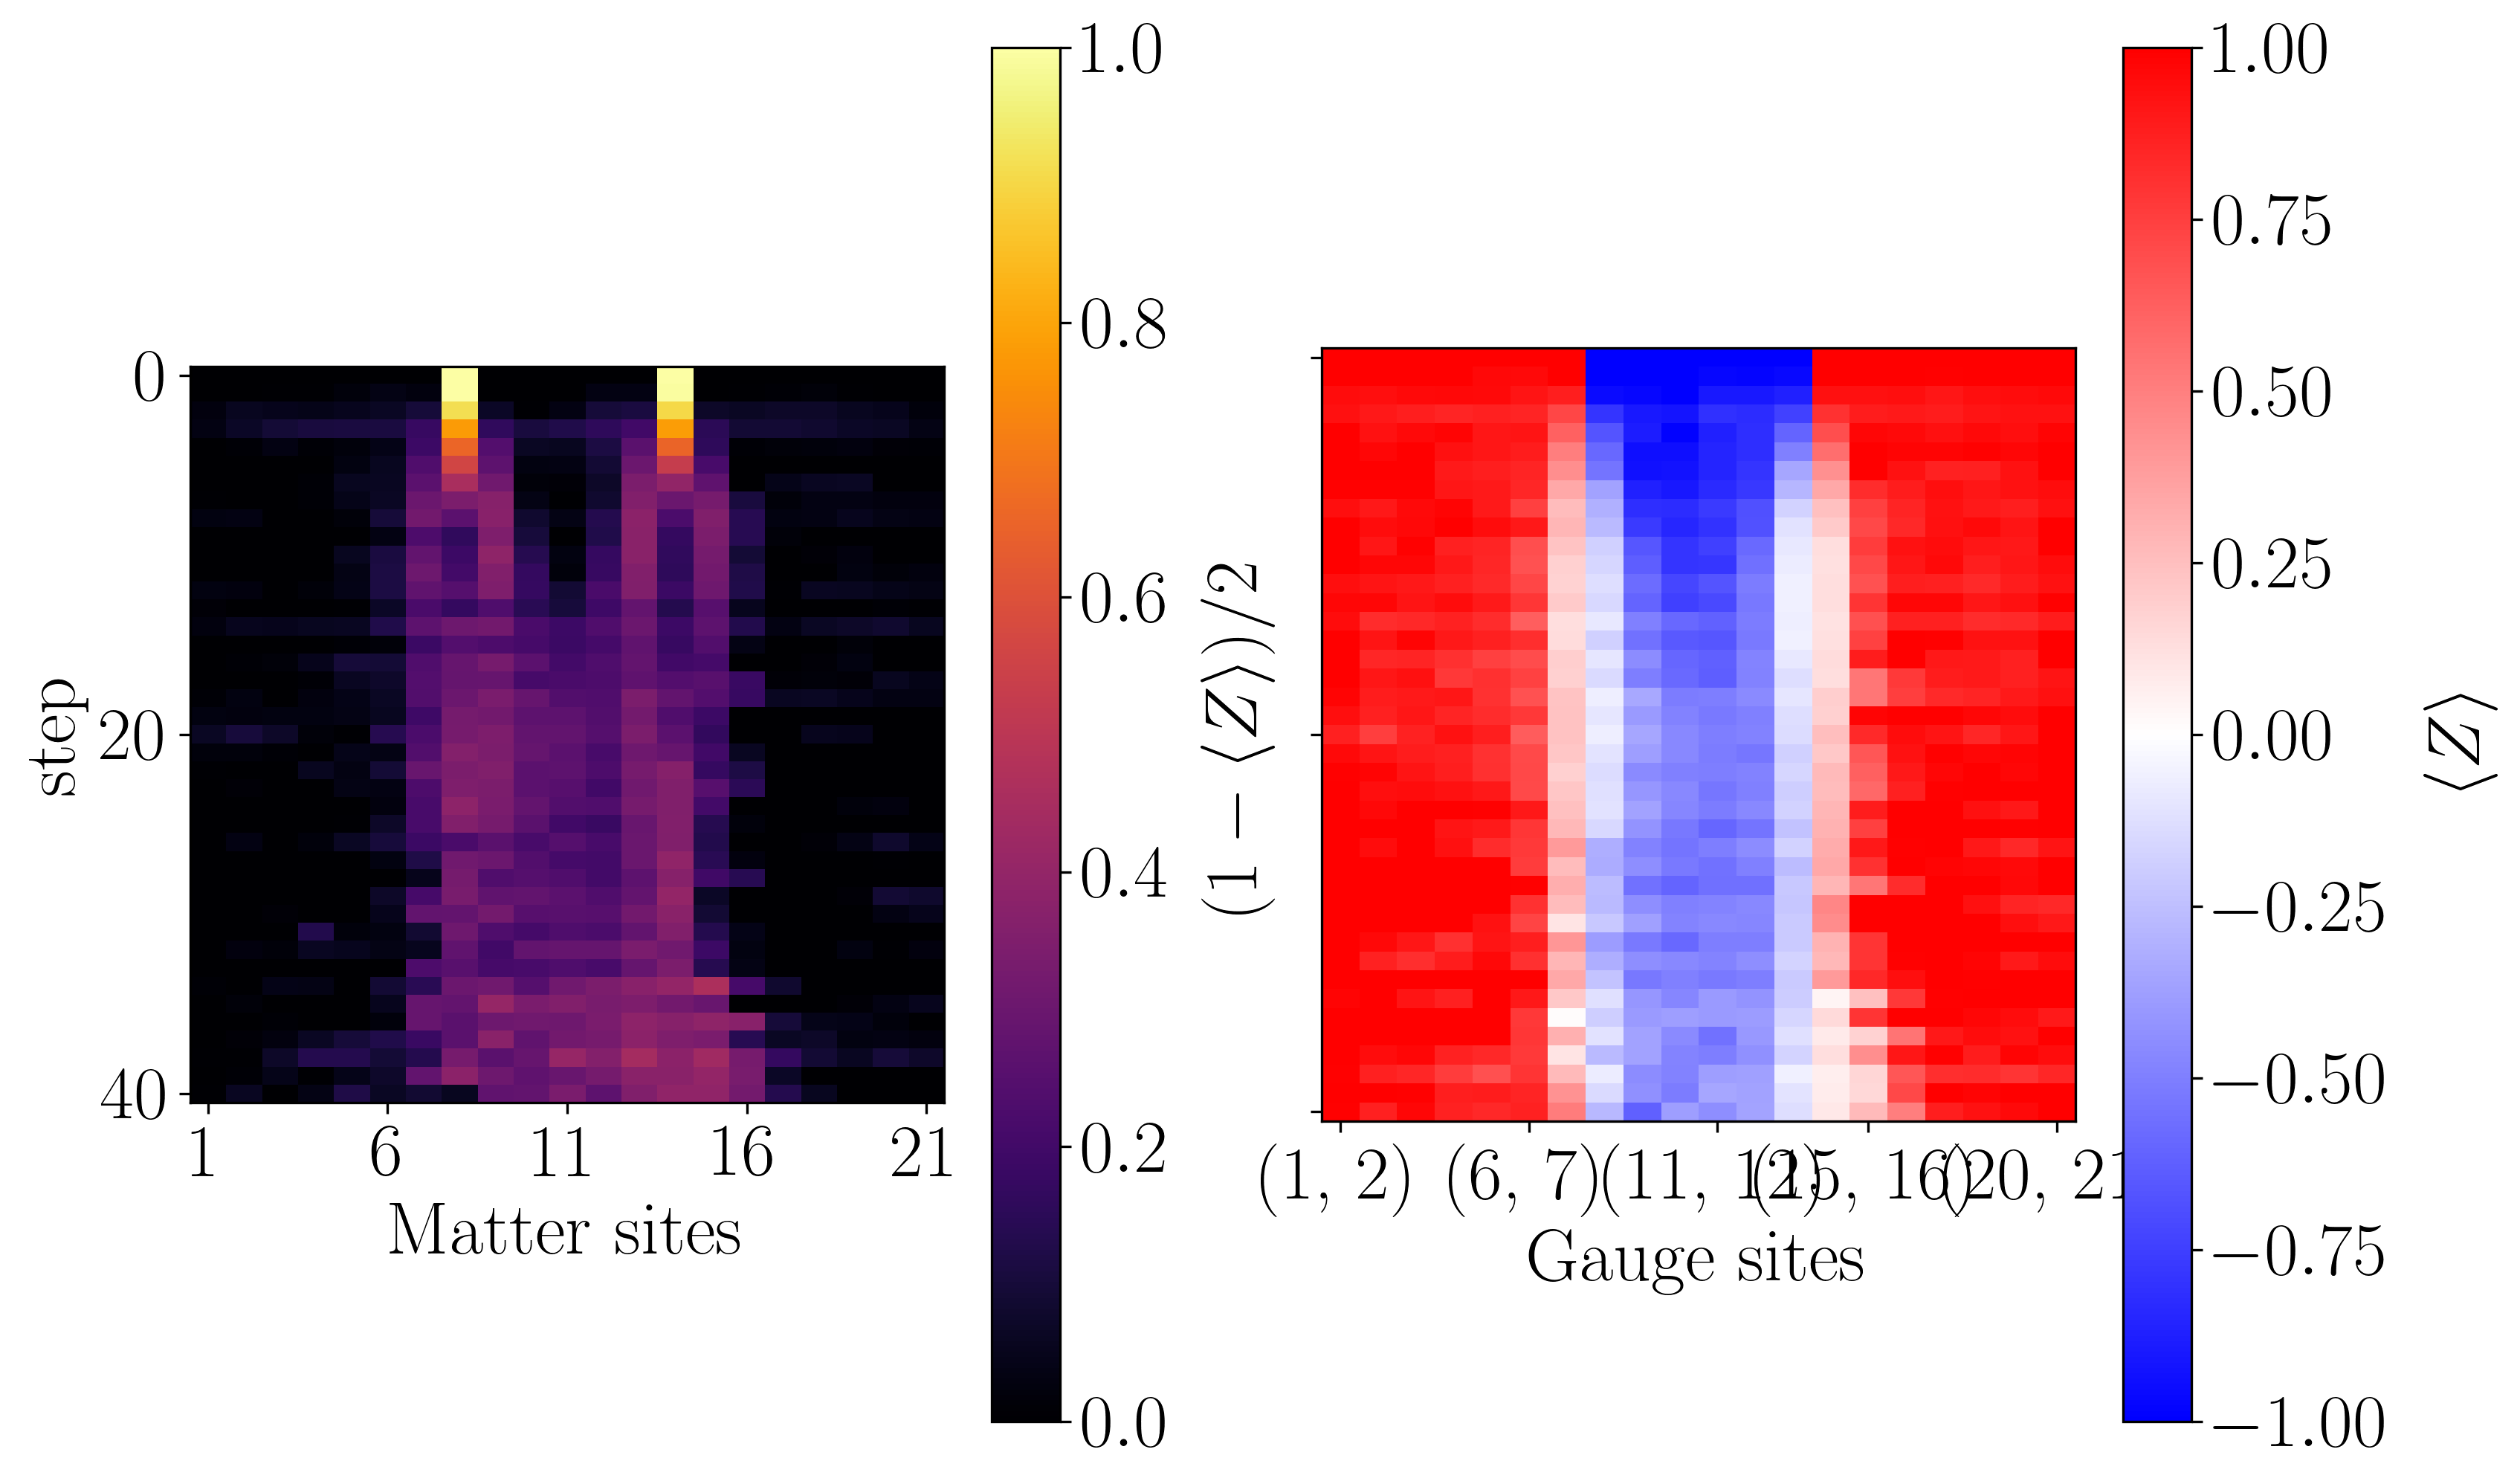

In [8]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observables, cbar_range_matter=(0, 1), cbar_range_gauge=(-1, 1))

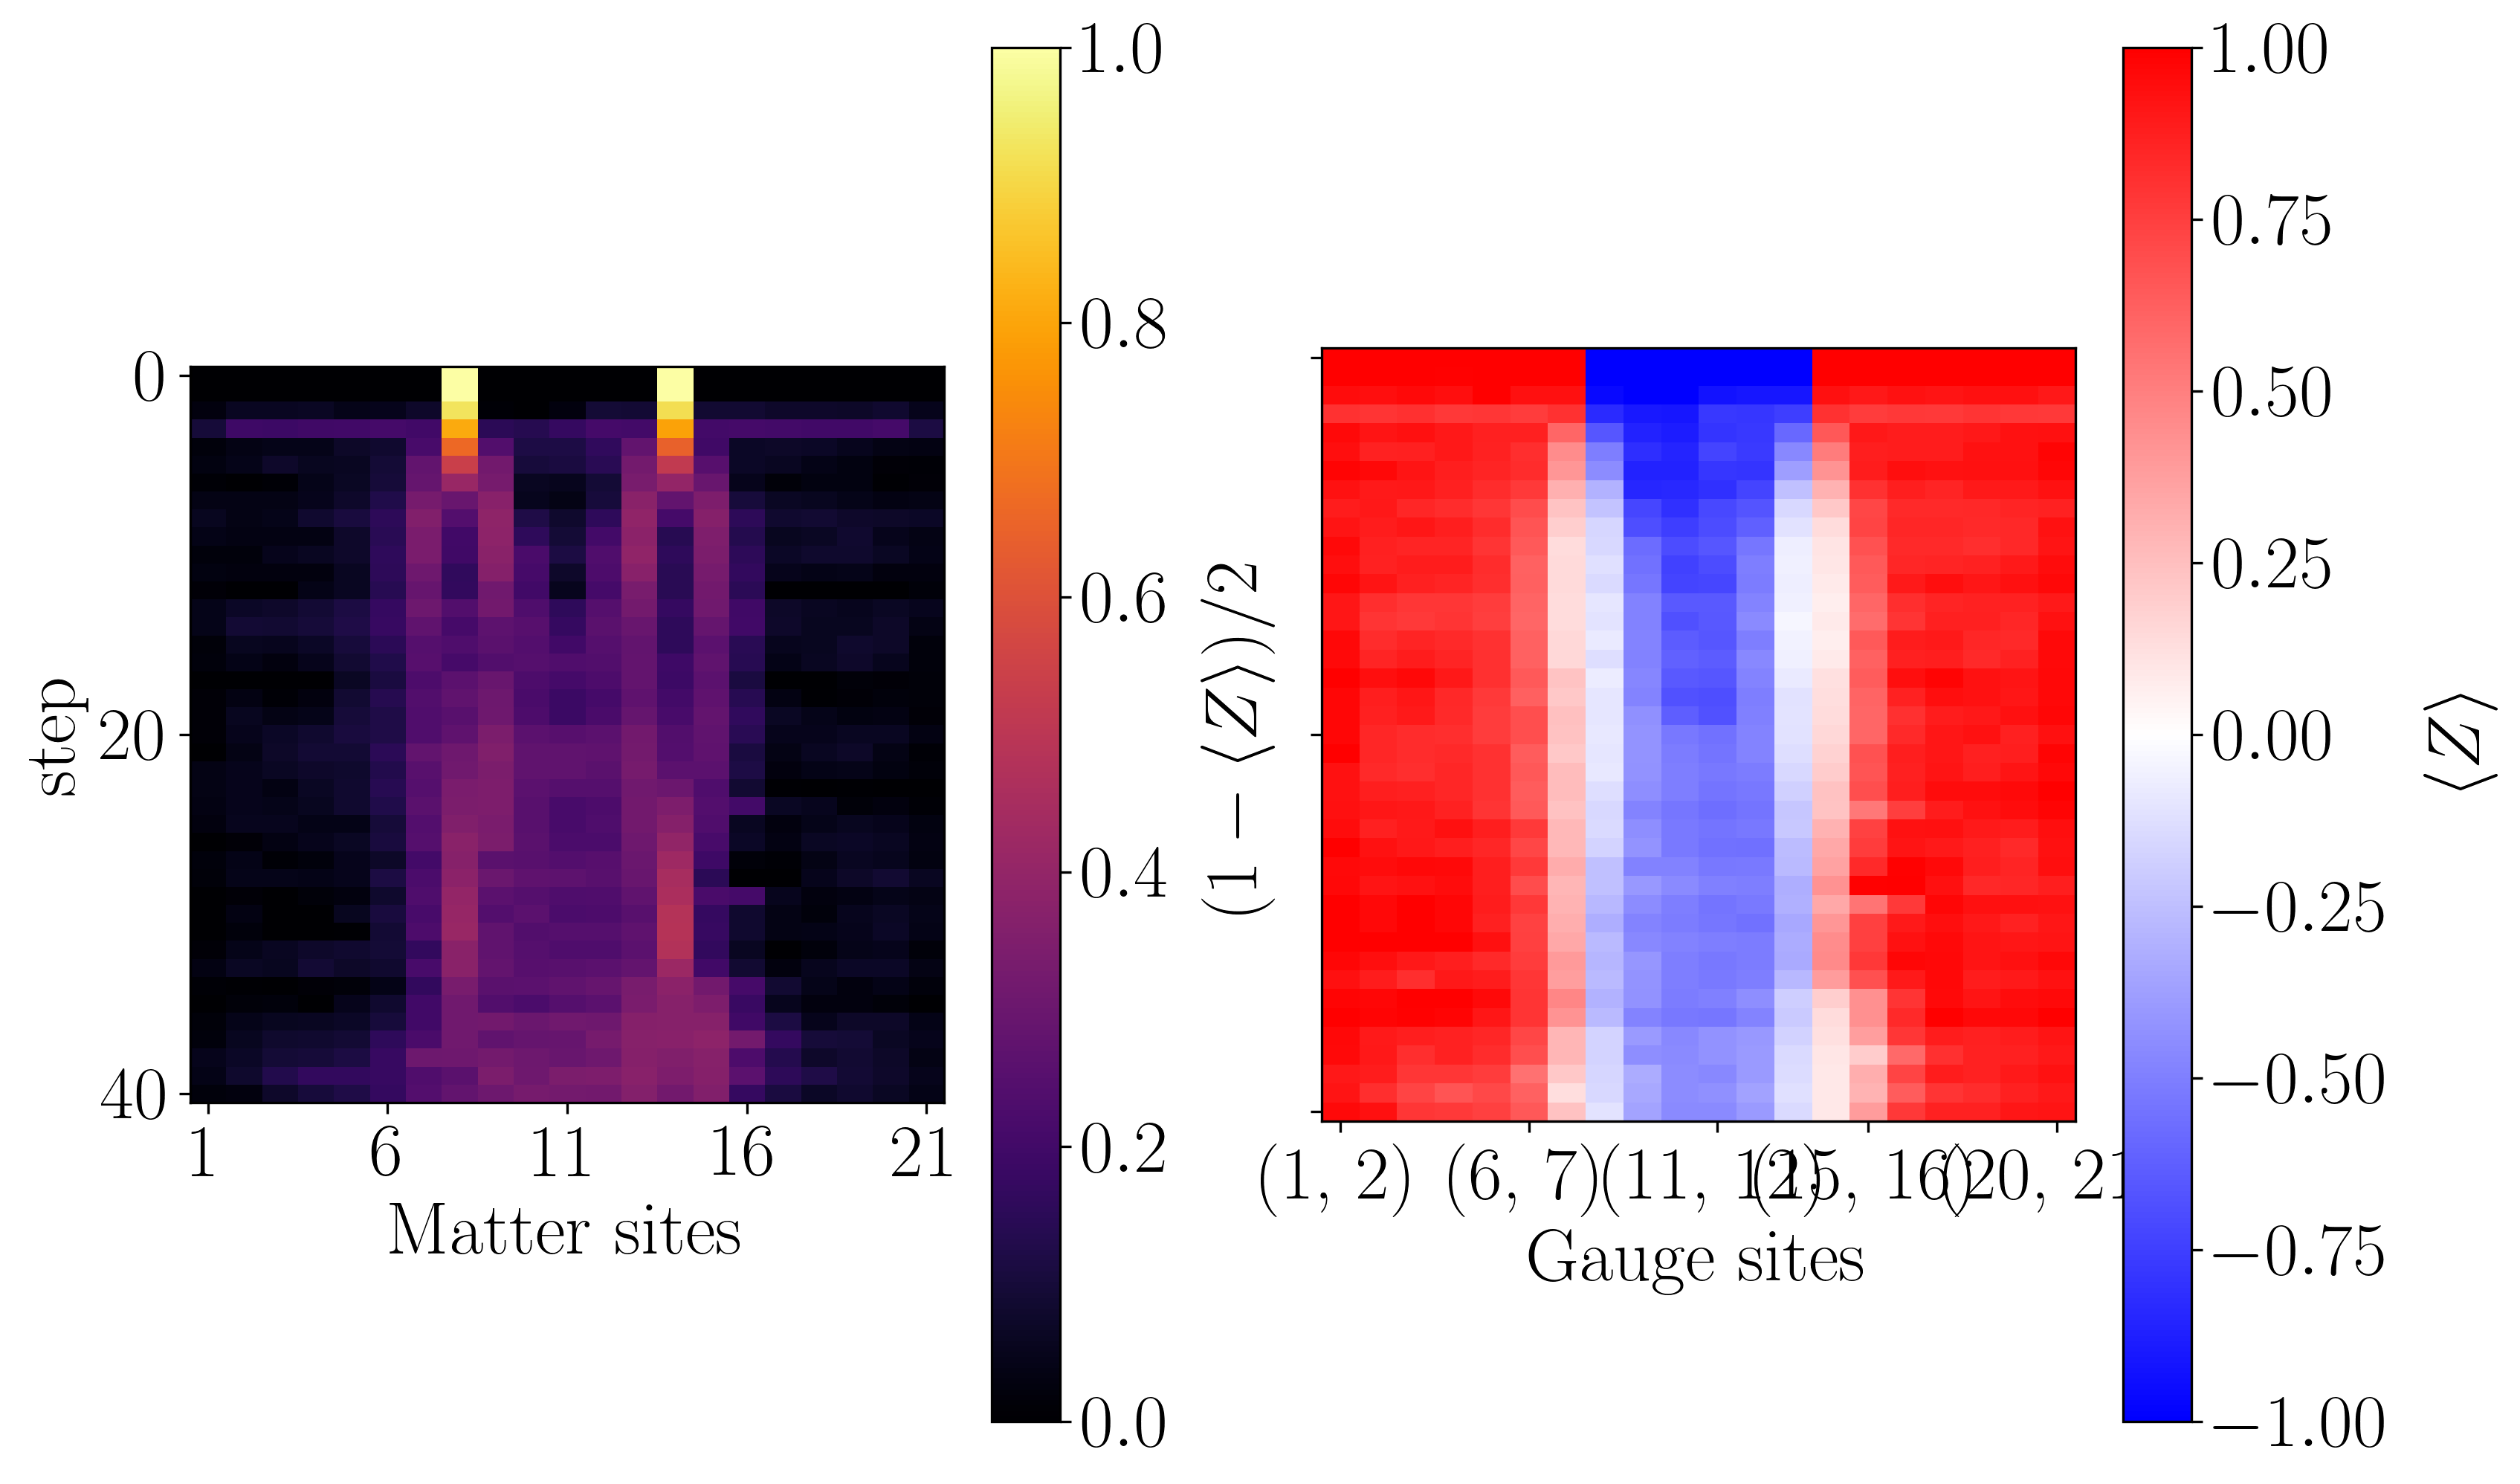

In [9]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(mpf_observables[0][::2, :], cbar_range_matter=(0, 1), cbar_range_gauge=(-1, 1))

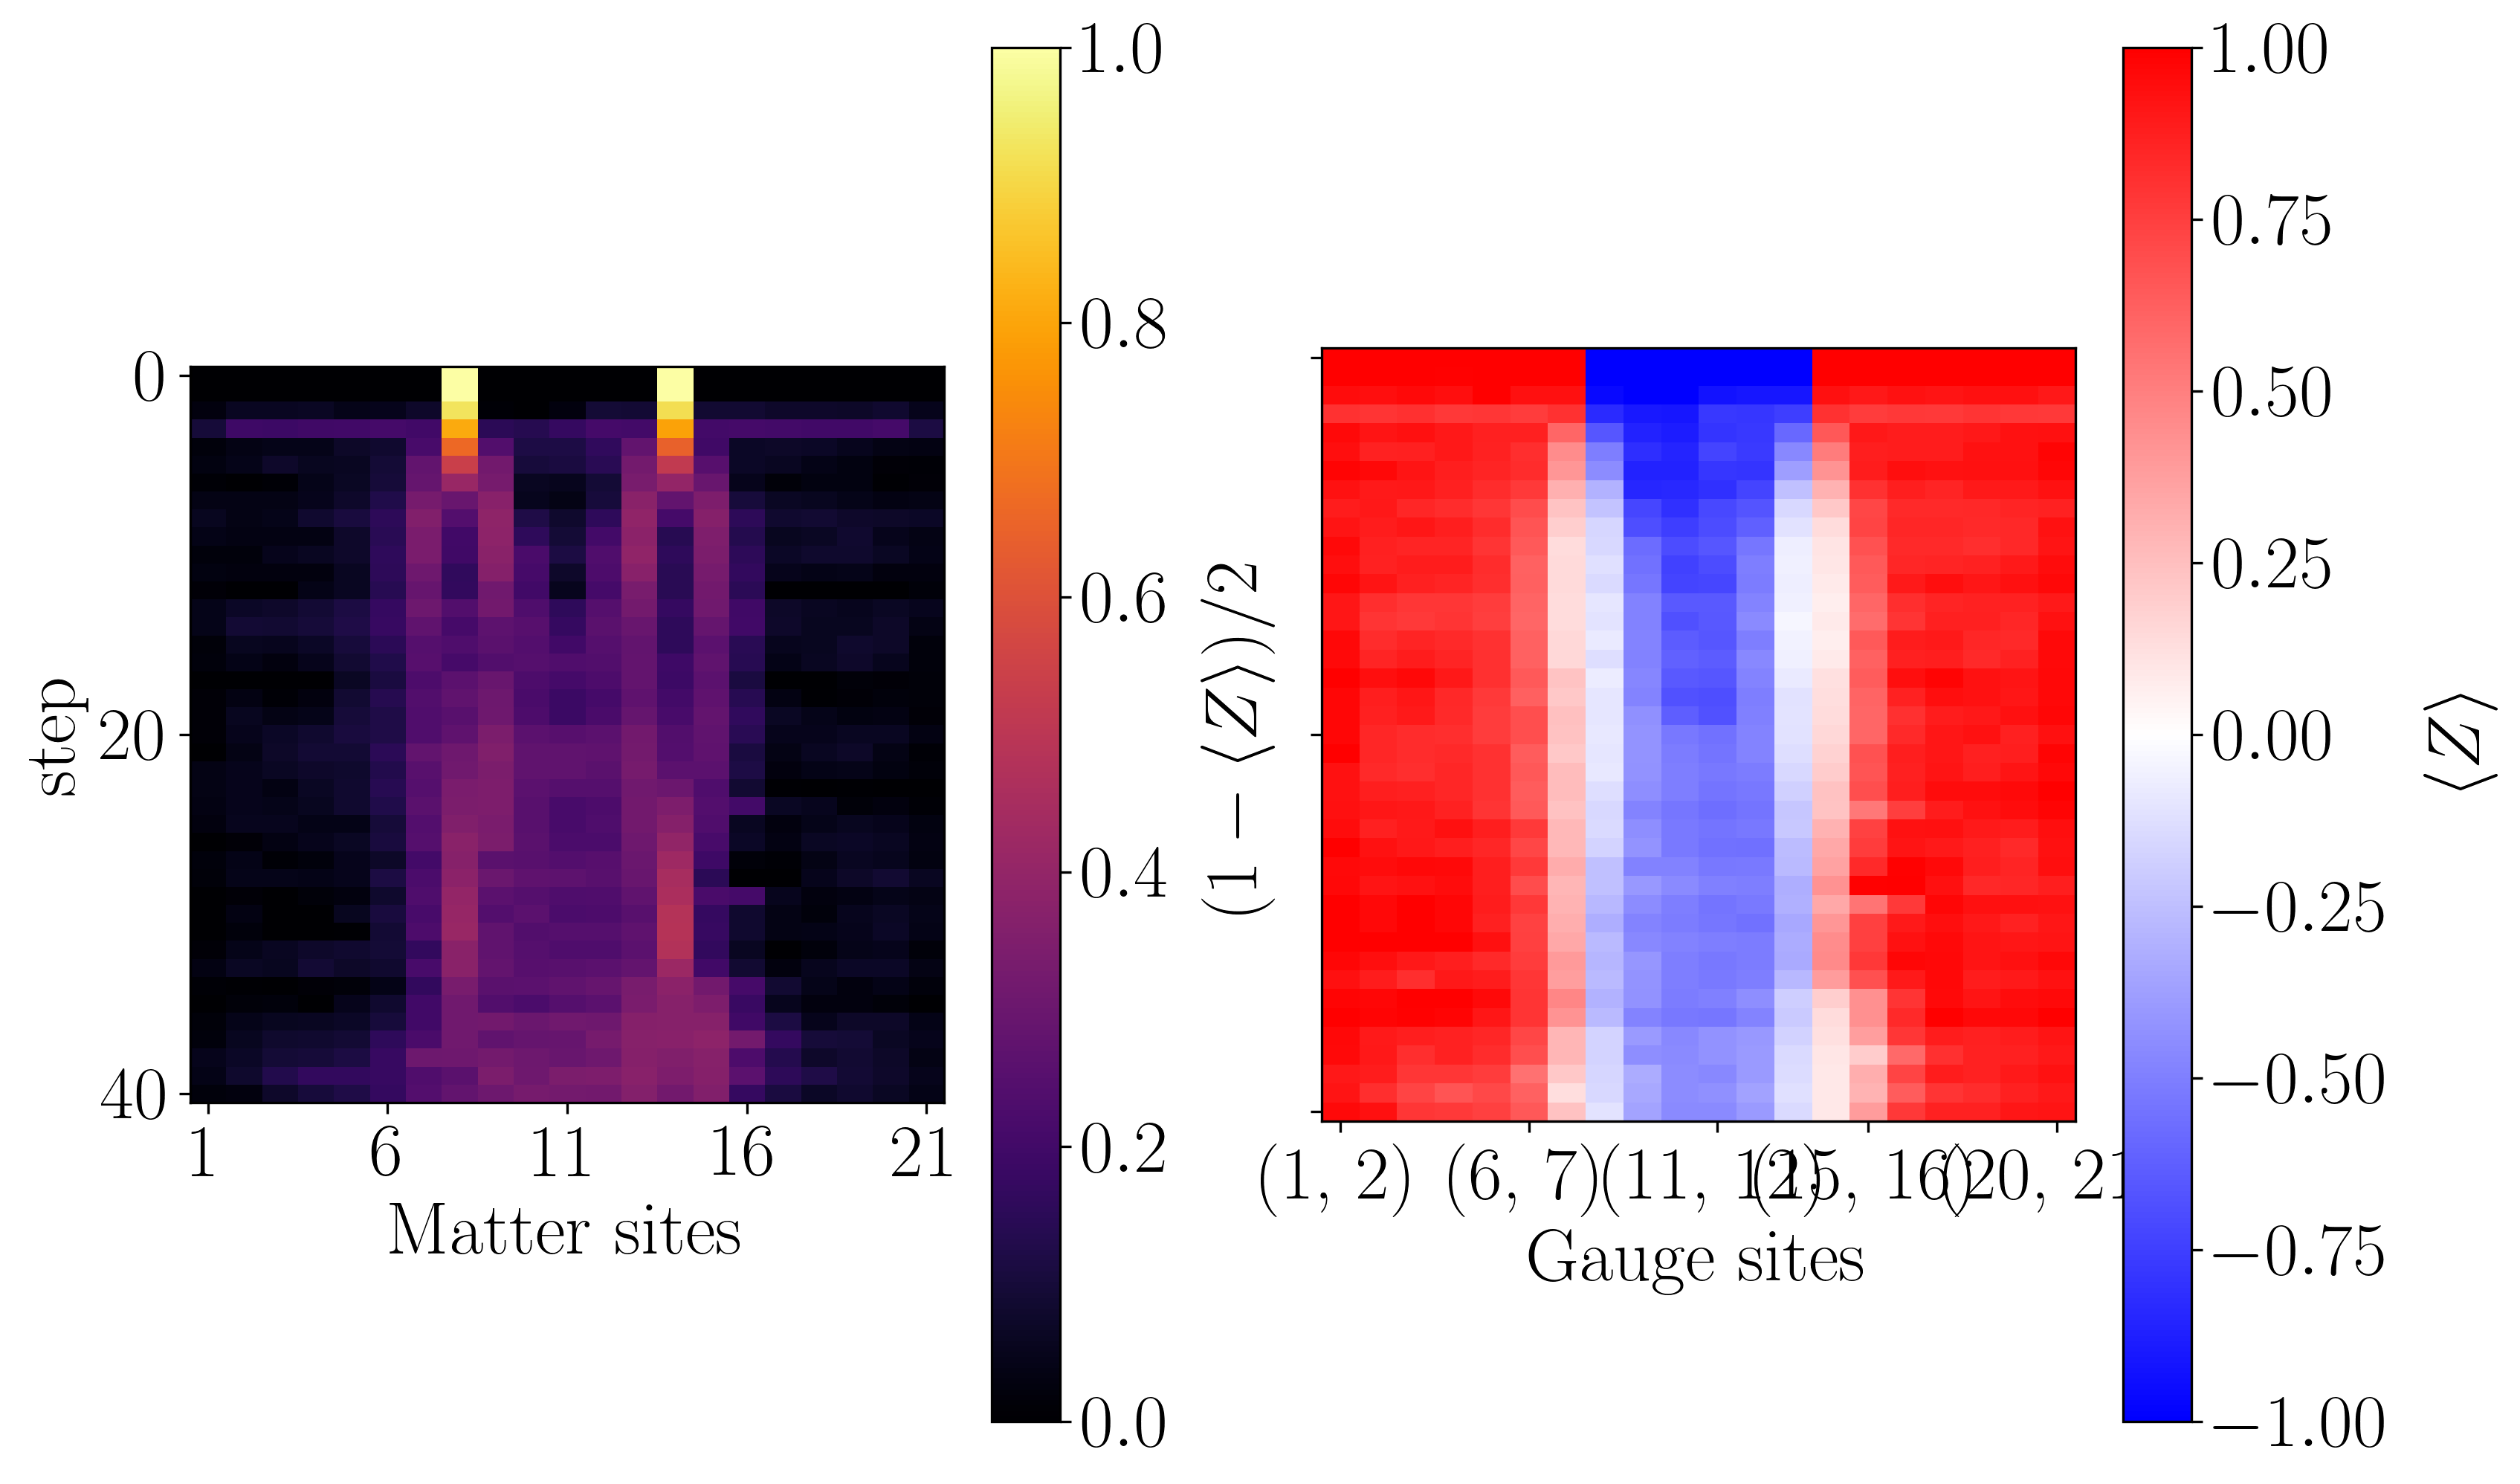

In [10]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(mpf_observables[0][0::2, :], cbar_range_matter=(0, 1), cbar_range_gauge=(-1, 1))

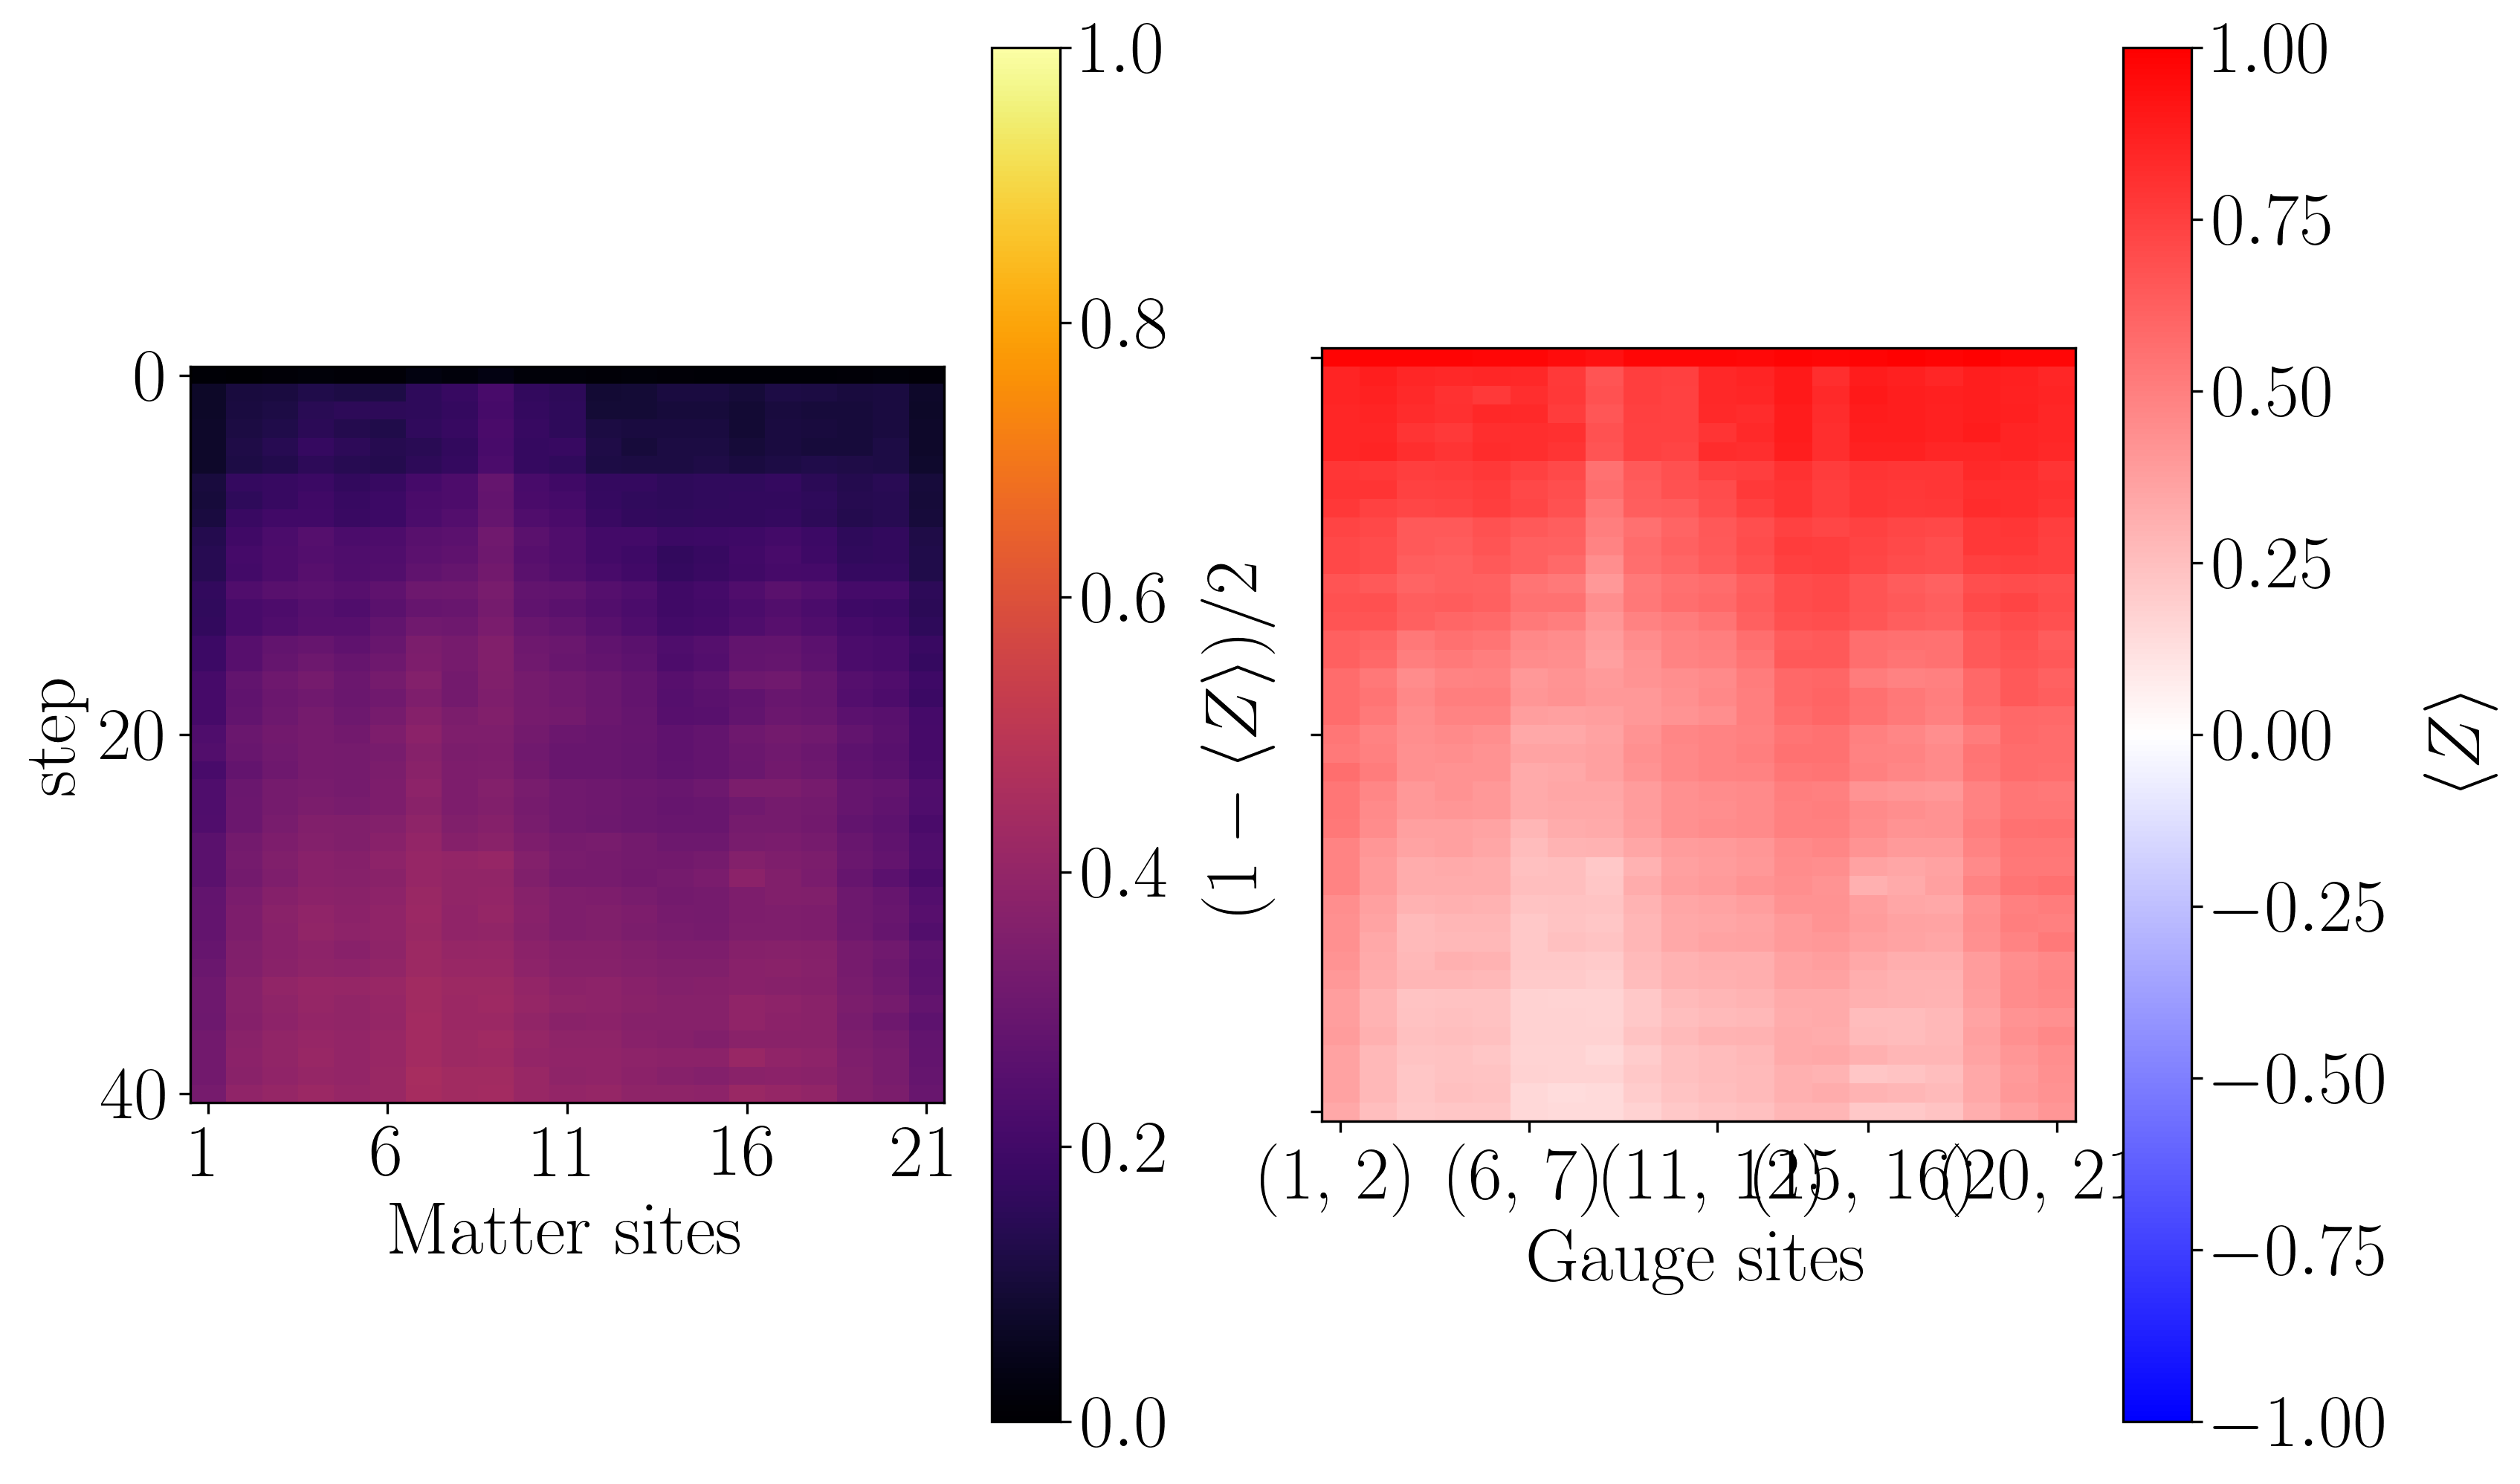

In [11]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(mpf_observables[2][0::2, :], cbar_range_matter=(0, 1), cbar_range_gauge=(-1, 1))

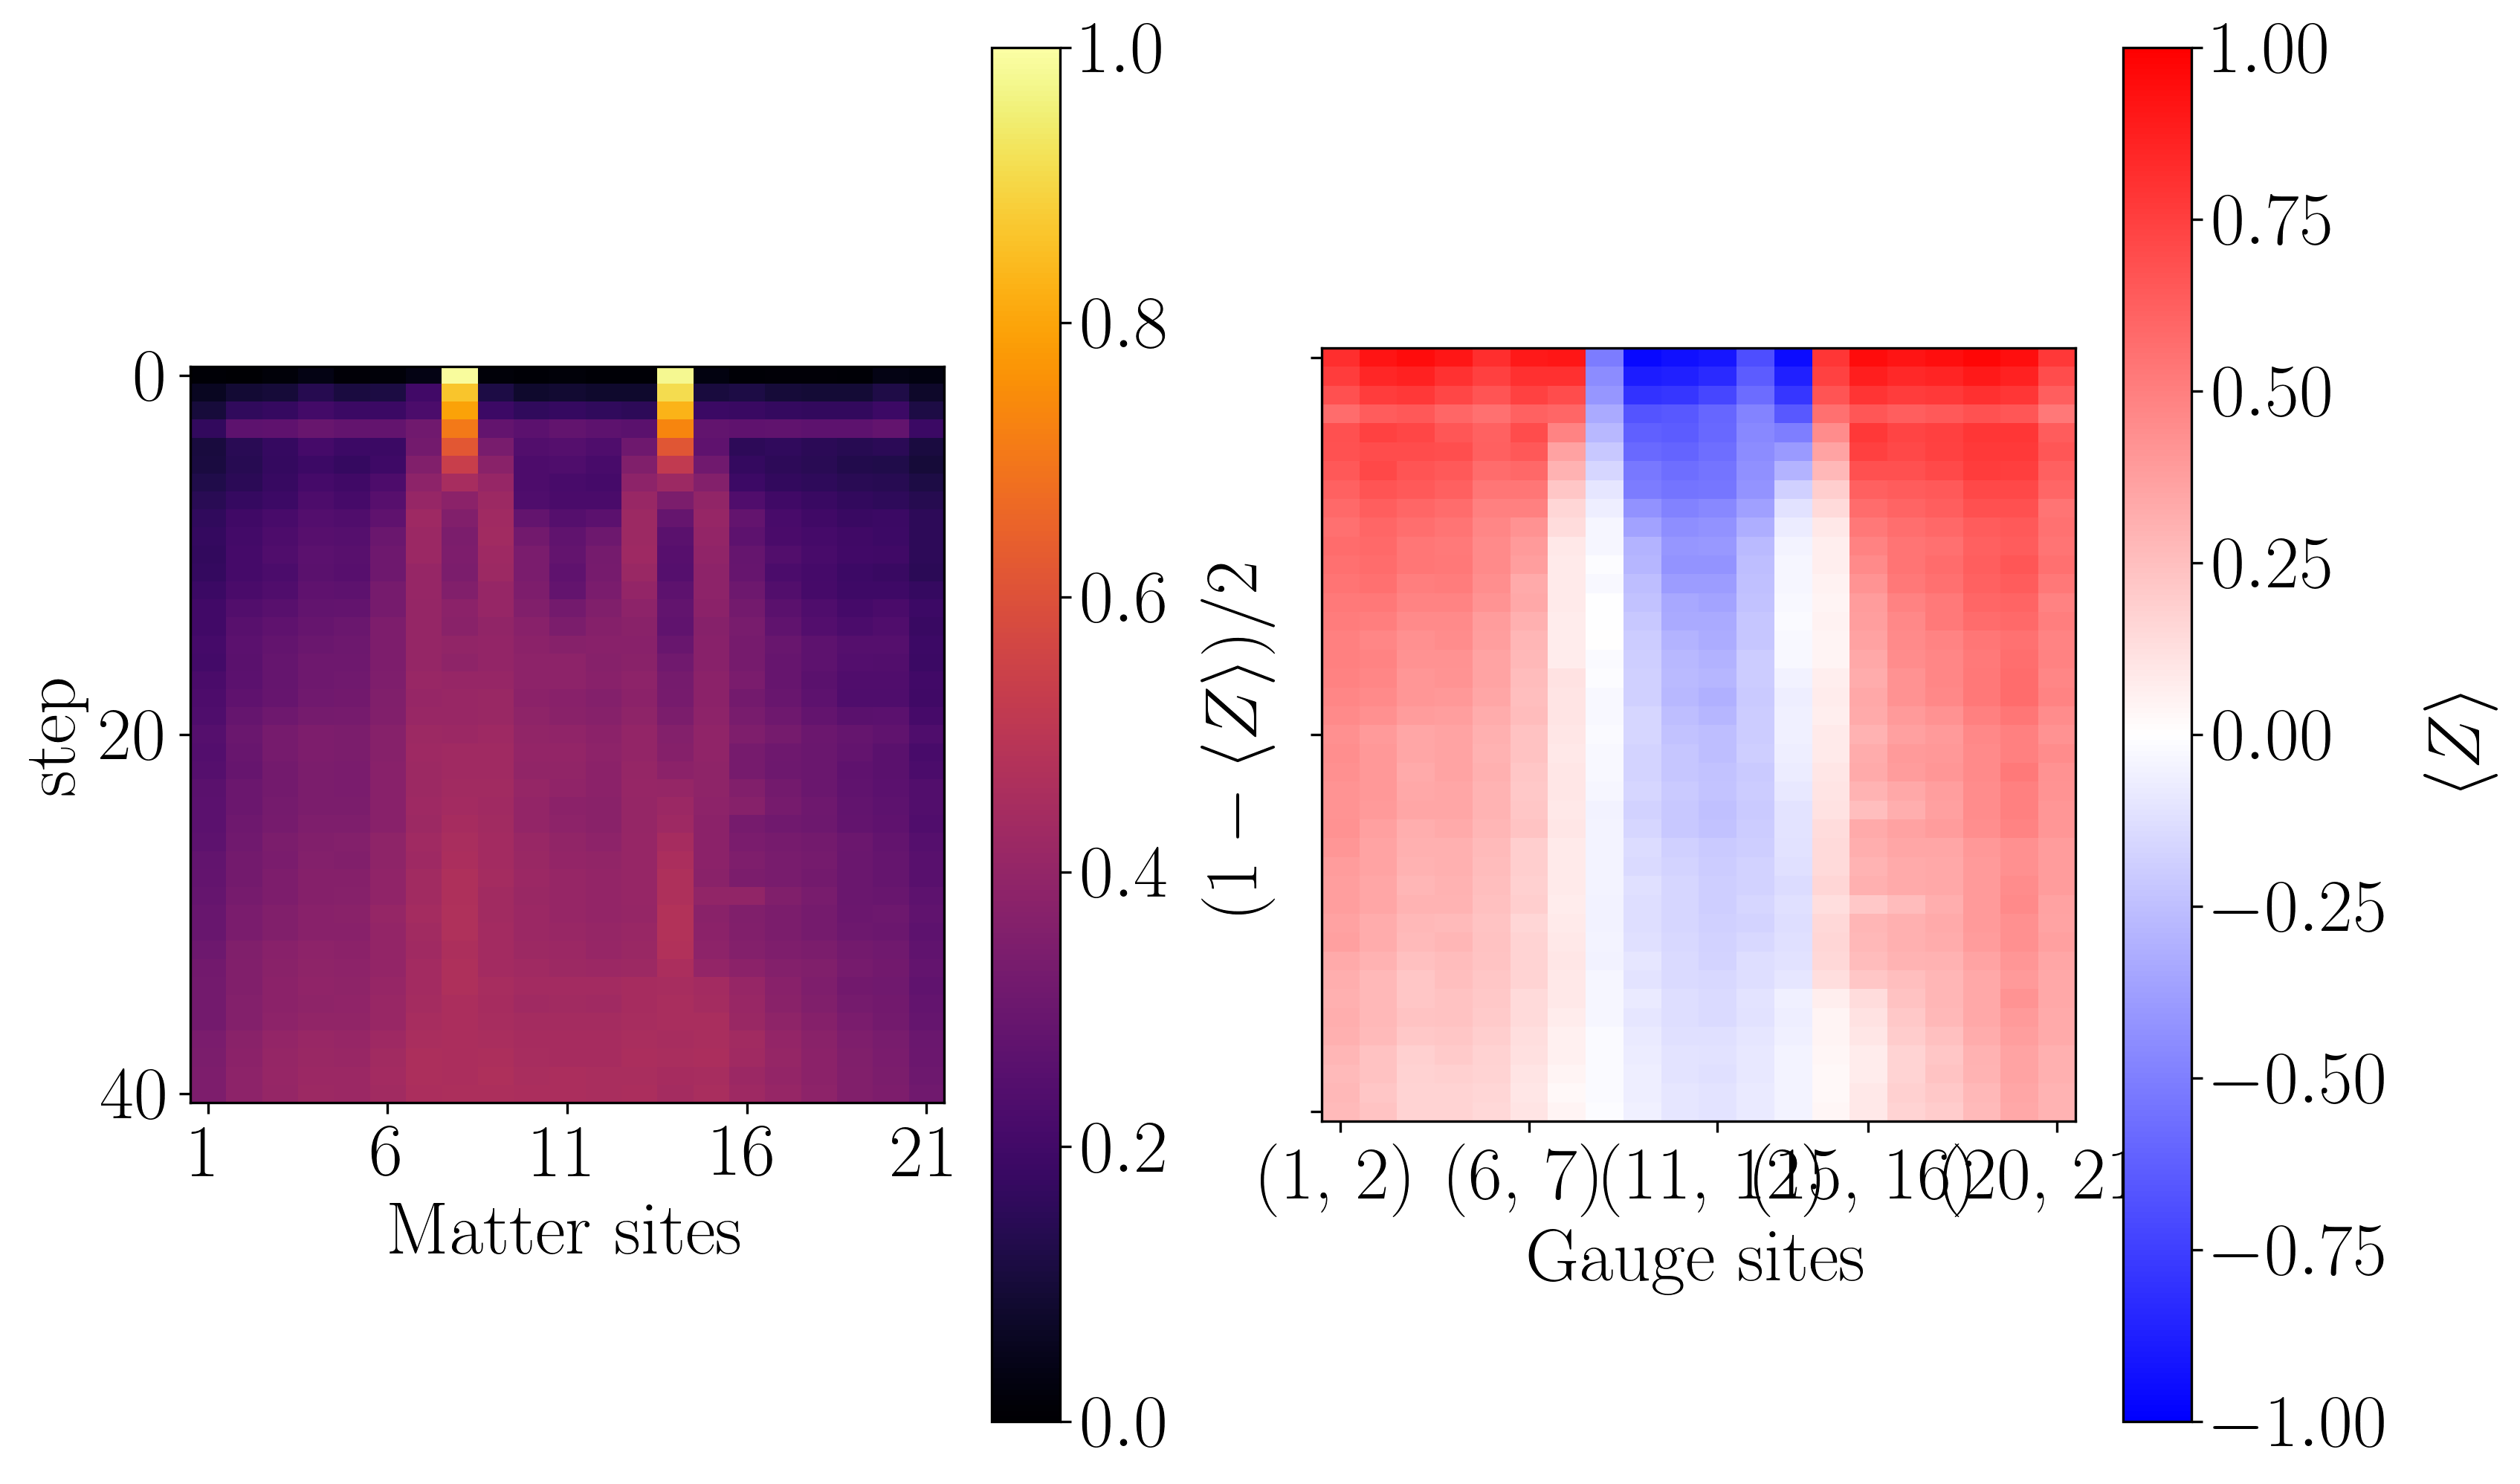

In [12]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(mpf_observables[3][0::2, :], cbar_range_matter=(0, 1), cbar_range_gauge=(-1, 1))